# Team \#1
## Workshop Open Tools — Vera Rubin Observatory

```Author: Diego Fonseca```

Last update date: 15/10/2026

**Ver este notebook en [Colab](https://colab.research.google.com/github/ale-munozarancibia/LSST_Hackdays_Medellin_Team1_Characterizing_DIAObjects/blob/main/Project/Team1_Crossmatch_ECDFS_Diego.ipynb)**

In [ ]:
# Consulta de alertas y objetos astronómicos
!pip install alerce

In [ ]:
# "Descargo una librería adicional que el notebook necesita"
!wget https://raw.githubusercontent.com/alercebroker/usecases/master/notebooks/LSST/lib_multisurvey/alerce_multisurvey_tools.py -P lib_multisurvey/

--2026-10-15 15:36:13--  https://raw.githubusercontent.com/alercebroker/usecases/master/notebooks/LSST/lib_multisurvey/alerce_multisurvey_tools.py
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 38849 (38K) [text/plain]
Saving to: ‘lib_multisurvey/alerce_multisurvey_tools.py.4’

alerce_multisurvey_ 100%[===================>]  37.94K  --.-KB/s    in 0.01s   

2026-10-15 15:36:14 (2.54 MB/s) - ‘lib_multisurvey/alerce_multisurvey_tools.py.4’ saved [38849/38849]



In [ ]:
# Librería de Python para acceder a servicios astronómicos basados en estándares del Virtual Observatory (VO)
!pip install pyvo

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from astropy.cosmology import Planck18
from astropy.time import Time              # Conversiones y manejo de fechas/tiempos astronómicos.
import pyvo                                # Consultas a servicios del Virtual Observatory.
import sys                                 # Permite modificar rutas de importación o acceder a información del entorno de Python.

In [ ]:
from alerce.core import Alerce             # Importa la clase principal del cliente de ALeRCE

In [ ]:
# Este bloque solo ajusta cómo se muestran las tablas en Google Colab/Jupyter
from IPython.core.display import HTML
pd.set_option('display.max_colwidth', 100)
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', 20)

In [ ]:
alerce_client = Alerce()         # crear el cliente que se conectará con ALeRCE.

In [ ]:
tid = 1

In [ ]:
TAP_URL = 'https://tap.alerce.online/tap'           # Guarda la dirección del servicio TAP de ALeRCE
tap_service = pyvo.dal.TAPService(TAP_URL)          # Crea un objeto tap_service que será el encargado de enviar consultas a ese servidor.

# Las consultas a ALeRCE terminarán directamente en un DataFrame de Pandas

def tap_query(query, maxrec=10_000_000):            # maxrec=10_000_000, permite recuperar hasta 10 millones de registros.
    result = tap_service.search(query, maxrec=maxrec)
    return result.to_table().to_pandas()

In [ ]:
# Región del cielo que vamos a explorar
# Coordenadas del centro de la región a explorar
ra = 52.98
dec = -28.12
radius = 1.78

In [ ]:
query = '''
SELECT
    o.*,
    tax.class_name,
    p.probability,
    p.ranking,
    p.classifier_id
FROM
    alerce_tap.object AS o                            -- Consulta la tabla de objetos de ALeRCE
JOIN
    alerce_tap.probability AS p
    ON o.oid = p.oid
    AND o.sid = p.sid
JOIN
    alerce_tap.taxonomy AS tax
    ON p.class_id = tax.class_id
    AND p.classifier_id = tax.classifier_id
WHERE
    o.tid = %d                                        -- Selecciona solo los objetos con tid=1,
                                                      -- Significa que estamos seleccionando objetos no móviles asociados a diaObject, que es justamente lo esperable para supernovas,
                                                      -- AGN y estrellas variables.
    AND CONTAINS(
        POINT('ICRS', o.meanra, o.meandec),
        CIRCLE('ICRS', %.7g, %.7g, %g)
    ) = 1
    AND o.sid = 1                                    -- Si fuera sid=2, se uyiliza para objetos en el Sistema Solar.
    AND p.ranking = 1
    AND p.classifier_id = 3
    AND tax.class_name IN ('SN', 'AGN')
    AND o.n_det >= 50
''' % (tid, ra, dec, radius)

df_obj = tap_query(query)
df_obj

,oid,tid,sid,meanra,meandec,sigmara,sigmadec,firstmjd,lastmjd,deltamjd,n_det,n_forced,n_non_det,created_date,updated_date,class_name,probability,ranking,classifier_id
0,313699514821640259,1,1,51.620550,-28.114119,1.914917e-07,1.884254e-07,60989.260516,61108.032716,118.772200,129,12,0,2026-02-13,2026-03-09,SN,0.965387,1,3
1,313928193878261820,1,1,52.558536,-29.216970,3.142184e-06,3.150095e-06,61041.220126,61060.119674,18.899548,59,0,0,2026-02-13,2026-02-24,SN,0.500874,1,3
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
72,313950161050533922,1,1,52.789899,-28.540200,1.609607e-06,1.537141e-06,61046.157250,61103.036815,56.879565,81,7,0,2026-02-13,2026-03-04,AGN,0.523554,1,3
73,313853499363295265,1,1,54.495240,-28.312829,1.163711e-06,1.182515e-06,61024.143738,61088.097015,63.953278,109,1,0,2026-02-13,2026-02-24,AGN,0.924924,1,3


In [ ]:
print(len(df_obj),len(pd.unique(df_obj['oid']))) # Verificamos que tengamos filas unicas para oid unicos

74 74


In [ ]:
mask = df_obj['oid']==313853499326070865
df_obj[mask]

,oid,tid,sid,meanra,meandec,sigmara,sigmadec,firstmjd,lastmjd,deltamjd,n_det,n_forced,n_non_det,created_date,updated_date,class_name,probability,ranking,classifier_id
16,313853499326070865,1,1,52.5861,-28.504675,0.000003,0.000003,61024.143738,61060.119674,35.975936,64,0,0,2026-02-13,2026-02-24,AGN,0.906235,1,3


In [ ]:
query_classifiers = '''
SELECT *
FROM alerce_tap.classifier
'''

df_classifiers = tap_query(query_classifiers)
df_classifiers

,classifier_id,classifier_name,classifier_version,tid,created_date
0,1,stamp_classifier_rubin_beta,2.0.1,1,2026-04-29
1,4,stamp_classifier,1.0.4,0,2026-05-28
2,3,stamp_classifier_rubin_beta_20260421,2.0.2,1,2026-05-28
3,2,stamp_classifier_2025_beta,2.1.1,0,2026-04-29
4,5,lc_classifier_BHRF_forced_phot,2.1.0,0,2026-07-03
5,6,lc_classifier_BHRF_forced_phot_top,2.1.0,0,2026-07-03
6,7,lc_classifier_BHRF_forced_phot_transient,2.1.0,0,2026-07-03
7,8,lc_classifier_BHRF_forced_phot_stochastic,2.1.0,0,2026-07-03
8,9,lc_classifier_BHRF_forced_phot_periodic,2.1.0,0,2026-07-03


La instrucción sid = 1, garantiza que sea un diaObjectid de Rubin.

In [ ]:
# Inspección visual de los candidatos seleccionados (Enlaces directos a la intreface de la red ALeRCE)
def print_link_lsst(index=None, classifier='stamp_classifier_rubin_beta_20260421'):
    if len(index) == 1:
        expr = 'https://lsst.alerce.online/object/' + str(index[0]) \
               + '?survey=lsst'
    else:
        expr1 = 'https://lsst.alerce.online/?oid='
        expr2 = ','.join(list([str(x) for x in index]))
        expr3 = '&survey=lsst'
        expr4 = '&classifier=' + classifier + '&page=1'
        expr = expr1 + expr2 + expr3 + expr4

    display(HTML("<a href='%s' target=\"_blank\"> %s <a>" % (expr, expr)))

Enlace que nos lleva a AleRCE, para ubicar los objetos que hemos seleccionado.

In [ ]:
print_link_lsst(index=df_obj['oid'])

Hasta este punto, ya tenemos dos cosas importantes: (1) df_obj: catálogo filtrado de 86 objetos Rubin. (2) Enlace para inspeccionar objetos visualmente con ALeRCE.

Ahora vamos a hacer el cruce de catálogos. Para ello utilizamos LSDB.

In [ ]:
!pip install nested_pandas              # Permite manejar columnas con estructuras anidadas, algo común en alertas.
!pip install hats                       # Trabaja con catálogos particionados espacialmente tipo HiPSCat.
!pip install lsdb                       # Es la librería con la que ya venimos haciendo los crossmatch espaciales.
!pip install dask distributed           # Permite procesar catálogos grandes de forma paralela y diferida.

In [ ]:
import os
import sys
import re
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nested_pandas as npd
import lsdb
import hats

from astropy.timeseries import LombScargle
from dask.distributed import Client
from sklearn.ensemble import IsolationForest
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import RobustScaler

pd.set_option("display.max_columns", 100)
print("Python executable:", sys.executable)
print("Conda environment:", os.environ.get("CONDA_DEFAULT_ENV"))
print("Python:", sys.version.split()[0])
print("LSDB:", lsdb.__version__)
print("HATS:", hats.__version__)
print("nested-pandas:", npd.__version__)

Python executable: /usr/bin/python3
Conda environment: None
Python: 3.13.16
LSDB: 0.11.0
HATS: 0.11.0
nested-pandas: 0.7.2


In [ ]:
try:
    client.close()
except Exception:
    pass

client = Client(n_workers=2, threads_per_worker=1, memory_limit="2GB")
client

INFO:distributed.scheduler:State start
INFO:distributed.scheduler:  Scheduler at:     tcp://127.0.0.1:40337
INFO:distributed.scheduler:  dashboard at:  http://127.0.0.1:8787/status
INFO:distributed.scheduler:Registering Worker plugin shuffle
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:33421'
INFO:distributed.nanny:        Start Nanny at: 'tcp://127.0.0.1:33653'
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:42641 name: 1
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:42641
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:35798
INFO:distributed.scheduler:Register worker addr: tcp://127.0.0.1:40361 name: 0
INFO:distributed.scheduler:Starting worker compute stream, tcp://127.0.0.1:40361
INFO:distributed.core:Starting established connection to tcp://127.0.0.1:35796
INFO:distributed.scheduler:Receive client connection: Client-ea189530-c8b5-11f1-823c-0242ac1c000c
INFO:distributed.core:Starting establish

Connection method: Cluster object,Cluster type: distributed.LocalCluster
Dashboard: http://127.0.0.1:8787/status,
Dashboard: http://127.0.0.1:8787/status,Workers: 2
Total threads: 2,Total memory: 3.73 GiB
Status: running,Using processes: True
Comm: tcp://127.0.0.1:40337,Workers: 0
Dashboard: http://127.0.0.1:8787/status,Total threads: 0
Started: Just now,Total memory: 0 B
Comm: tcp://127.0.0.1:40361,Total threads: 1
Dashboard: http://127.0.0.1:36557/status,Memory: 1.86 GiB
Nanny: tcp://127.0.0.1:33421,


In [ ]:
TNS_PATH = "https://data.lsdb.io/hats/tns/"

FIELDS = {
    "ELAIS-S1": (9.45, -44.02),
    "XMM-LSS": (35.57, -4.82),
    "ECDFS": (52.98, -28.12),
    "COSMOS": (150.11, 2.23),
    "EDFS-a": (58.90, -49.32),
    "EDFS-b": (63.60, -47.60),
}

FIELD = "ECDFS"

RA0, DEC0 = FIELDS[FIELD]

# Mismo radio utilizado para construir df_obj en ALeRCE
RADIUS_DEG = 1.78
RADIUS_ARCSEC = RADIUS_DEG * 3600.0

# Radio para considerar una coincidencia TNS-Rubin
MATCH_RADIUS_ARCSEC = 1.0

cone = lsdb.ConeSearch(
    RA0,
    DEC0,
    radius_arcsec=RADIUS_ARCSEC
)

print("Field:", FIELD)
print("Center:", RA0, DEC0)
print("Search radius [deg]:", RADIUS_DEG)
print("Search radius [arcsec]:", RADIUS_ARCSEC)
print("Match radius [arcsec]:", MATCH_RADIUS_ARCSEC)

Field: ECDFS
Center: 52.98 -28.12
Search radius [deg]: 1.78
Search radius [arcsec]: 6408.0
Match radius [arcsec]: 1.0


In [ ]:
TNS_meta = lsdb.open_catalog(TNS_PATH)

print("TNS columns:", list(TNS_meta.columns))

print("df_obj columns:", df_obj.columns.tolist())
print("df_obj shape:", df_obj.shape)
display(df_obj.head(10))

TNS columns: ['objid', 'name_prefix', 'name', 'ra', 'declination', 'redshift', 'typeid', 'type', 'reporting_groupid', 'reporting_group', 'source_groupid', 'source_group', 'discoverydate', 'discoverymag', 'discmagfilter', 'filter', 'reporters', 'time_received', 'internal_names', 'Discovery_ADS_bibcode', 'Class_ADS_bibcodes', 'creationdate', 'lastmodified']
df_obj columns: ['oid', 'tid', 'sid', 'meanra', 'meandec', 'sigmara', 'sigmadec', 'firstmjd', 'lastmjd', 'deltamjd', 'n_det', 'n_forced', 'n_non_det', 'created_date', 'updated_date', 'class_name', 'probability', 'ranking', 'classifier_id']
df_obj shape: (74, 19)


,oid,tid,sid,meanra,meandec,sigmara,sigmadec,firstmjd,lastmjd,deltamjd,n_det,n_forced,n_non_det,created_date,updated_date,class_name,probability,ranking,classifier_id
0,313699514821640259,1,1,51.620550,-28.114119,1.914917e-07,1.884254e-07,60989.260516,61108.032716,118.772200,129,12,0,2026-02-13,2026-03-09,SN,0.965387,1,3
1,313928193878261820,1,1,52.558536,-29.216970,3.142184e-06,3.150095e-06,61041.220126,61060.119674,18.899548,59,0,0,2026-02-13,2026-02-24,SN,0.500874,1,3
2,313677517043531799,1,1,52.372406,-28.705124,2.131295e-06,2.023052e-06,60984.251250,61088.097015,103.845765,56,1,0,2026-02-13,2026-02-24,SN,0.981978,1,3
3,313928193953234970,1,1,54.648409,-27.699329,5.958089e-07,6.076746e-07,61041.220126,61103.036815,61.816689,78,6,0,2026-02-13,2026-03-04,SN,0.685611,1,3
4,313853499427782700,1,1,53.677609,-29.526403,1.229188e-06,1.276612e-06,61024.144244,61069.082988,44.938744,93,0,0,2026-02-13,2026-02-24,SN,0.869342,1,3
5,313835835847344147,1,1,51.829329,-28.883339,1.010572e-06,9.955089e-07,61020.239796,61069.082988,48.843192,104,0,0,2026-02-13,2026-02-24,SN,0.580908,1,3
6,313695088894541868,1,1,52.375185,-29.338986,2.317735e-06,2.293909e-06,60988.139636,61060.119674,71.980038,74,0,0,2026-02-13,2026-02-24,SN,0.781145,1,3
7,313835835598831657,1,1,53.208400,-27.576608,1.511988e-06,1.557218e-06,61020.238594,61088.097446,67.858853,54,2,0,2026-02-13,2026-02-24,SN,0.984450,1,3
8,313853499338129416,1,1,51.989818,-27.560444,2.628814e-06,2.740469e-06,61024.143738,61060.119674,35.975936,72,0,0,2026-02-13,2026-02-24,SN,0.511103,1,3
9,313994139532263447,1,1,53.251366,-27.861040,4.406122e-07,3.751695e-07,61056.119070,61108.033147,51.914077,52,14,0,2026-02-13,2026-03-09,SN,0.972766,1,3


In [ ]:
try:
    client.close()
except Exception:
    pass

client = None

INFO:distributed.scheduler:Remove client Client-ea189530-c8b5-11f1-823c-0242ac1c000c
INFO:distributed.core:Received 'close-stream' from tcp://127.0.0.1:35804; closing.
INFO:distributed.scheduler:Remove client Client-ea189530-c8b5-11f1-823c-0242ac1c000c
INFO:distributed.scheduler:Close client connection: Client-ea189530-c8b5-11f1-823c-0242ac1c000c
INFO:distributed.scheduler:Retire worker addresses (stimulus_id='retire-workers-1792081931.44436') (0, 1)
INFO:distributed.nanny:Closing Nanny at 'tcp://127.0.0.1:33421'. Reason: nanny-close
INFO:distributed.nanny:Nanny asking worker to close. Reason: nanny-close
INFO:distributed.nanny:Closing Nanny at 'tcp://127.0.0.1:33653'. Reason: nanny-close
INFO:distributed.nanny:Nanny asking worker to close. Reason: nanny-close
INFO:distributed.core:Received 'close-stream' from tcp://127.0.0.1:35796; closing.
INFO:distributed.scheduler:Remove worker addr: tcp://127.0.0.1:40361 name: 0 (stimulus_id='handle-worker-cleanup-1792081931.4540172')
INFO:distrib

In [ ]:
print(
    TNS_meta[
        ['objid', 'name', 'ra', 'declination', 'type']
    ].head()
)

print(
    df_obj[
        ['oid', 'meanra', 'meandec', 'n_det',
         'class_name', 'probability', 'ranking']
    ].head(10)
)

Computing Catalog:   0%|          | 0/2 [00:00<?, ?it/s]

                     objid      name         ra  declination  type
_healpix_29                                                       
68585540087357627   222932  2019abaq  43.662462     34.20133  <NA>
183607005620922064  222902  2026afkj  12.016443    36.980758  <NA>
45708930450826041   222323  2026aesa  27.253953      16.8268  <NA>
159567083821244209  222833  2026afhu  23.826229    36.426158  <NA>
149058056168314642  222844  2026afif  28.782182    27.166672  <NA>
                  oid     meanra    meandec  n_det class_name  probability  \
0  313699514821640259  51.620550 -28.114119    129         SN     0.965387   
1  313928193878261820  52.558536 -29.216970     59         SN     0.500874   
2  313677517043531799  52.372406 -28.705124     56         SN     0.981978   
3  313928193953234970  54.648409 -27.699329     78         SN     0.685611   
4  313853499427782700  53.677609 -29.526403     93         SN     0.869342   
5  313835835847344147  51.829329 -28.883339    104         SN  

In [ ]:
TNS_REQUESTED = [
    "objid", "name", "ra", "declination", "redshift", "type",
]

TNS_columns = [
    x for x in TNS_REQUESTED
    if x in TNS_meta.columns
]

TNS = lsdb.open_catalog(
    TNS_PATH,
    columns=TNS_columns,
    search_filter=cone
)

print("Selected TNS columns:", TNS_columns)

print("Selected Rubin columns:")
print(
    df_obj[
        ["oid", "meanra", "meandec", "n_det", "firstmjd", "lastmjd"]
    ].columns.tolist()
)

Selected TNS columns: ['objid', 'name', 'ra', 'declination', 'redshift', 'type']
Selected Rubin columns:
['oid', 'meanra', 'meandec', 'n_det', 'firstmjd', 'lastmjd']


In [ ]:
display(TNS.head(10))
display(df_obj.head(10))

Computing Catalog:   0%|          | 0/2 [00:00<?, ?it/s]

,objid,name,ra,declination,redshift,type
_healpix_29,,,,,,
2530347163341259087,221789,2026adyj,51.66174,-27.278248,<NA>,<NA>
2542288376342219771,221576,2026adqj,53.701974,-26.9119,<NA>,<NA>
2528522415176561738,215006,2026vam,53.839212,-29.109954,<NA>,<NA>
2528756305343135099,219871,2026abft,53.399575,-27.764428,<NA>,<NA>
2528744040834540654,218884,2024aijv,53.295834,-27.879179,<NA>,<NA>
2528749616910093990,218384,2023aegm,53.10838,-27.881138,<NA>,<NA>
2528496625705124811,218377,2026zhg,53.559991,-29.679958,<NA>,<NA>
2528749804665103185,218317,2023aegl,53.037117,-27.884743,<NA>,<NA>
2530194775628323083,218080,2025amzi,51.892809,-28.092408,<NA>,<NA>


,oid,tid,sid,meanra,meandec,sigmara,sigmadec,firstmjd,lastmjd,deltamjd,n_det,n_forced,n_non_det,created_date,updated_date,class_name,probability,ranking,classifier_id
0,313699514821640259,1,1,51.620550,-28.114119,1.914917e-07,1.884254e-07,60989.260516,61108.032716,118.772200,129,12,0,2026-02-13,2026-03-09,SN,0.965387,1,3
1,313928193878261820,1,1,52.558536,-29.216970,3.142184e-06,3.150095e-06,61041.220126,61060.119674,18.899548,59,0,0,2026-02-13,2026-02-24,SN,0.500874,1,3
2,313677517043531799,1,1,52.372406,-28.705124,2.131295e-06,2.023052e-06,60984.251250,61088.097015,103.845765,56,1,0,2026-02-13,2026-02-24,SN,0.981978,1,3
3,313928193953234970,1,1,54.648409,-27.699329,5.958089e-07,6.076746e-07,61041.220126,61103.036815,61.816689,78,6,0,2026-02-13,2026-03-04,SN,0.685611,1,3
4,313853499427782700,1,1,53.677609,-29.526403,1.229188e-06,1.276612e-06,61024.144244,61069.082988,44.938744,93,0,0,2026-02-13,2026-02-24,SN,0.869342,1,3
5,313835835847344147,1,1,51.829329,-28.883339,1.010572e-06,9.955089e-07,61020.239796,61069.082988,48.843192,104,0,0,2026-02-13,2026-02-24,SN,0.580908,1,3
6,313695088894541868,1,1,52.375185,-29.338986,2.317735e-06,2.293909e-06,60988.139636,61060.119674,71.980038,74,0,0,2026-02-13,2026-02-24,SN,0.781145,1,3
7,313835835598831657,1,1,53.208400,-27.576608,1.511988e-06,1.557218e-06,61020.238594,61088.097446,67.858853,54,2,0,2026-02-13,2026-02-24,SN,0.984450,1,3
8,313853499338129416,1,1,51.989818,-27.560444,2.628814e-06,2.740469e-06,61024.143738,61060.119674,35.975936,72,0,0,2026-02-13,2026-02-24,SN,0.511103,1,3
9,313994139532263447,1,1,53.251366,-27.861040,4.406122e-07,3.751695e-07,61056.119070,61108.033147,51.914077,52,14,0,2026-02-13,2026-03-09,SN,0.972766,1,3


In [ ]:
# Materializar el catálogo TNS dentro de la región seleccionada
TNS_region = TNS.compute()

print(f"TNS sources in {FIELD}: {len(TNS_region):,}")
display(TNS_region.head(20))

# Revisar la distribución de clasificaciones TNS
display(
    TNS_region["type"]
    .value_counts(dropna=False)
    .head(30)
)

# Subconjunto de objetos TNS con clasificación disponible
TNS_classified = TNS_region[
    TNS_region["type"].notna()
].copy()

print("TNS classified sources:", len(TNS_classified))

display(
    TNS_classified[
        ["objid", "name", "type", "redshift", "ra", "declination"]
    ].head(30)
)

Computing Catalog:   0%|          | 0/2 [00:00<?, ?it/s]

TNS sources in ECDFS: 264


,objid,name,ra,declination,redshift,type
_healpix_29,,,,,,
2530347163341259087,221789,2026adyj,51.66174,-27.278248,<NA>,<NA>
2542288376342219771,221576,2026adqj,53.701974,-26.9119,<NA>,<NA>
2528522415176561738,215006,2026vam,53.839212,-29.109954,<NA>,<NA>
2528756305343135099,219871,2026abft,53.399575,-27.764428,<NA>,<NA>
2528744040834540654,218884,2024aijv,53.295834,-27.879179,<NA>,<NA>
2528749616910093990,218384,2023aegm,53.10838,-27.881138,<NA>,<NA>
2528496625705124811,218377,2026zhg,53.559991,-29.679958,<NA>,<NA>
2528749804665103185,218317,2023aegl,53.037117,-27.884743,<NA>,<NA>
2530194775628323083,218080,2025amzi,51.892809,-28.092408,<NA>,<NA>


,count
type,
<NA>,257
SN Ia,3
SN Ic-BL,1
SN IIn,1
SN Ia-91T-like,1
AGN,1


TNS classified sources: 7


,objid,name,type,redshift,ra,declination
_healpix_29,,,,,,
2528750857523882386,152773,2023adta,SN Ic-BL,2.83,53.135283,-27.814517
2528744355156762981,202412,2026eqf,SN IIn,0.147,53.251362,-27.861039
2528734992909640030,138569,2023vcn,SN Ia-91T-like,0.086,53.822802,-27.75106
2528609619908138115,96263,2021aele,SN Ia,0.077,53.885683,-28.51431
2542305740432370192,28896,2018fcv,AGN,0.094,54.023082,-26.607675
2528469495267257028,74638,2021go,SN Ia,0.1,51.744652,-29.140774
2540759440820961440,72885,2020acmi,SN Ia,0.055,54.667635,-27.196861


In [ ]:
def first_existing(columns, candidates, contains=None):
    """Return the first matching column name from a list of candidates."""
    columns = list(columns)

    for candidate in candidates:
        if candidate in columns:
            return candidate

    if contains is not None:
        matches = [
            c for c in columns
            if contains.lower() in str(c).lower()
        ]
        if matches:
            return matches[0]

    return None


def safe_to_parquet(frame, filename):
    """Save a pandas DataFrame or nested-pandas NestedFrame to Parquet."""
    try:
        frame.to_parquet(filename, index=False)

    except TypeError as error:
        if "unexpected keyword argument 'index'" not in str(error):
            raise

        frame.to_parquet(filename)

    print(f"Saved: {filename}")

In [ ]:
RUBIN_REQUESTED = [
    "oid",
    "meanra",
    "meandec",
    "n_det",
    "firstmjd",
    "lastmjd",
]

rubin_columns = [
    x for x in RUBIN_REQUESTED
    if x in df_obj.columns
]

rubin_obj = df_obj[rubin_columns].copy()

print("Selected Rubin columns:", rubin_columns)
print("Rubin objects:", len(rubin_obj))

display(rubin_obj.head())

Selected Rubin columns: ['oid', 'meanra', 'meandec', 'n_det', 'firstmjd', 'lastmjd']
Rubin objects: 74


,oid,meanra,meandec,n_det,firstmjd,lastmjd
0,313699514821640259,51.620550,-28.114119,129,60989.260516,61108.032716
1,313928193878261820,52.558536,-29.216970,59,61041.220126,61060.119674
2,313677517043531799,52.372406,-28.705124,56,60984.251250,61088.097015
3,313928193953234970,54.648409,-27.699329,78,61041.220126,61103.036815
4,313853499427782700,53.677609,-29.526403,93,61024.144244,61069.082988


In [ ]:
from astropy.coordinates import SkyCoord
import astropy.units as u

# Usar el df_obj actual, que ya contiene:
# class_name, probability, classifier_id, etc.
rubin_obj = df_obj.copy()

# Coordenadas TNS
coord_tns = SkyCoord(
    ra=TNS_region["ra"].to_numpy() * u.deg,
    dec=TNS_region["declination"].to_numpy() * u.deg
)

# Coordenadas de tus objetos Rubin
coord_rubin = SkyCoord(
    ra=rubin_obj["meanra"].to_numpy() * u.deg,
    dec=rubin_obj["meandec"].to_numpy() * u.deg
)

# Para cada objeto Rubin, buscar el objeto TNS más cercano
idx_tns, sep2d, _ = coord_rubin.match_to_catalog_sky(coord_tns)

# Construir tabla de resultados
rubin_tns = rubin_obj.copy()

rubin_tns["tns_objid"] = TNS_region.iloc[idx_tns]["objid"].to_numpy()
rubin_tns["tns_name"] = TNS_region.iloc[idx_tns]["name"].to_numpy()
rubin_tns["tns_type"] = TNS_region.iloc[idx_tns]["type"].to_numpy()
rubin_tns["tns_redshift"] = TNS_region.iloc[idx_tns]["redshift"].to_numpy()

rubin_tns["tns_ra"] = TNS_region.iloc[idx_tns]["ra"].to_numpy()
rubin_tns["tns_dec"] = TNS_region.iloc[idx_tns]["declination"].to_numpy()

rubin_tns["tns_rubin_dist_arcsec"] = sep2d.arcsec

rubin_tns["tns_match_ok"] = (
    rubin_tns["tns_rubin_dist_arcsec"] <= MATCH_RADIUS_ARCSEC
)

print(rubin_tns.shape)
display(rubin_tns.head())

(74, 27)


,oid,tid,sid,meanra,meandec,sigmara,sigmadec,firstmjd,lastmjd,deltamjd,n_det,n_forced,n_non_det,created_date,updated_date,class_name,probability,ranking,classifier_id,tns_objid,tns_name,tns_type,tns_redshift,tns_ra,tns_dec,tns_rubin_dist_arcsec,tns_match_ok
0,313699514821640259,1,1,51.620550,-28.114119,1.914917e-07,1.884254e-07,60989.260516,61108.032716,118.772200,129,12,0,2026-02-13,2026-03-09,SN,0.965387,1,3,196050,2025aijl,<NA>,NaN,51.620544,-28.114076,0.153674,True
1,313928193878261820,1,1,52.558536,-29.216970,3.142184e-06,3.150095e-06,61041.220126,61060.119674,18.899548,59,0,0,2026-02-13,2026-02-24,SN,0.500874,1,3,174781,2024ahuo,<NA>,NaN,52.716146,-28.990469,954.285790,False
2,313677517043531799,1,1,52.372406,-28.705124,2.131295e-06,2.023052e-06,60984.251250,61088.097015,103.845765,56,1,0,2026-02-13,2026-02-24,SN,0.981978,1,3,143780,2024fw,<NA>,NaN,52.374047,-28.704065,6.432422,False
3,313928193953234970,1,1,54.648409,-27.699329,5.958089e-07,6.076746e-07,61041.220126,61103.036815,61.816689,78,6,0,2026-02-13,2026-03-04,SN,0.685611,1,3,202795,2026fbw,<NA>,NaN,54.648408,-27.699328,0.003441,True
4,313853499427782700,1,1,53.677609,-29.526403,1.229188e-06,1.276612e-06,61024.144244,61069.082988,44.938744,93,0,0,2026-02-13,2026-02-24,SN,0.869342,1,3,203170,2025alvs,<NA>,NaN,53.677617,-29.526406,0.026582,True


In [ ]:
print("Total Rubin objects:", len(rubin_tns))
print("Valid TNS matches:", rubin_tns["tns_match_ok"].sum())
print(
    "Match fraction:",
    rubin_tns["tns_match_ok"].mean()
)

Total Rubin objects: 74
Valid TNS matches: 12
Match fraction: 0.16216216216216217


In [ ]:
rubin_tns_matches = rubin_tns[
    rubin_tns["tns_match_ok"]
].copy()

display(
    rubin_tns_matches[
        [
            "oid",
            "meanra",
            "meandec",
            "n_det",
            "tns_objid",
            "tns_name",
            "tns_type",
            "tns_redshift",
            "tns_rubin_dist_arcsec",
        ]
    ].sort_values("tns_rubin_dist_arcsec")
)

,oid,meanra,meandec,n_det,tns_objid,tns_name,tns_type,tns_redshift,tns_rubin_dist_arcsec
3,313928193953234970,54.648409,-27.699329,78,202795,2026fbw,<NA>,NaN,0.003441
12,313879818462560268,52.226852,-28.618031,98,204482,2025amka,<NA>,NaN,0.007878
8,313853499338129416,51.989818,-27.560444,72,207393,2025ammj,<NA>,NaN,0.009133
72,313950161050533922,52.789899,-28.540200,81,202644,2026ewn,<NA>,NaN,0.011622
9,313994139532263447,53.251366,-27.861040,52,202412,2026eqf,SN IIn,0.147,0.013825
53,313677517048250401,51.892813,-28.092412,55,218080,2025amzi,<NA>,NaN,0.018230
50,313756671181062188,53.923861,-29.222972,83,218077,2025amzf,<NA>,NaN,0.022604
4,313853499427782700,53.677609,-29.526403,93,203170,2025alvs,<NA>,NaN,0.026582
7,313835835598831657,53.208400,-27.576608,54,200549,2025alry,<NA>,NaN,0.083974
44,313756671195217941,52.786107,-27.341357,80,200543,2025alrt,<NA>,NaN,0.085315


In [ ]:
display(
    TNS_region["type"]
    .value_counts(dropna=False)
    .head(50)
)

,count
type,
<NA>,257
SN Ia,3
SN Ic-BL,1
SN IIn,1
SN Ia-91T-like,1
AGN,1


In [ ]:
# Trabajar sobre el resultado actual del crossmatch Rubin × TNS
rubin_tns_norm = rubin_tns.copy()

# Renombrar columnas Rubin para que el catálogo quede más claro
rename_roles = {
    "oid": "rubin_oid",
    "meanra": "rubin_ra",
    "meandec": "rubin_dec",
    "n_det": "rubin_n_det",
    "class_name": "rubin_class",
    "probability": "rubin_probability",
    "classifier_id": "rubin_classifier_id",
}

# Renombrar solo las columnas que realmente existan
rename_roles = {
    old: new
    for old, new in rename_roles.items()
    if old in rubin_tns_norm.columns
}

rubin_tns_norm = rubin_tns_norm.rename(columns=rename_roles)

print("Renamed columns:")
print(rename_roles)

print("\nNormalized columns:")
print(rubin_tns_norm.columns.tolist())

display(rubin_tns_norm.head())

Renamed columns:
{'oid': 'rubin_oid', 'meanra': 'rubin_ra', 'meandec': 'rubin_dec', 'n_det': 'rubin_n_det', 'class_name': 'rubin_class', 'probability': 'rubin_probability', 'classifier_id': 'rubin_classifier_id'}

Normalized columns:
['rubin_oid', 'tid', 'sid', 'rubin_ra', 'rubin_dec', 'sigmara', 'sigmadec', 'firstmjd', 'lastmjd', 'deltamjd', 'rubin_n_det', 'n_forced', 'n_non_det', 'created_date', 'updated_date', 'rubin_class', 'rubin_probability', 'ranking', 'rubin_classifier_id', 'tns_objid', 'tns_name', 'tns_type', 'tns_redshift', 'tns_ra', 'tns_dec', 'tns_rubin_dist_arcsec', 'tns_match_ok']


,rubin_oid,tid,sid,rubin_ra,rubin_dec,sigmara,sigmadec,firstmjd,lastmjd,deltamjd,rubin_n_det,n_forced,n_non_det,created_date,updated_date,rubin_class,rubin_probability,ranking,rubin_classifier_id,tns_objid,tns_name,tns_type,tns_redshift,tns_ra,tns_dec,tns_rubin_dist_arcsec,tns_match_ok
0,313699514821640259,1,1,51.620550,-28.114119,1.914917e-07,1.884254e-07,60989.260516,61108.032716,118.772200,129,12,0,2026-02-13,2026-03-09,SN,0.965387,1,3,196050,2025aijl,<NA>,NaN,51.620544,-28.114076,0.153674,True
1,313928193878261820,1,1,52.558536,-29.216970,3.142184e-06,3.150095e-06,61041.220126,61060.119674,18.899548,59,0,0,2026-02-13,2026-02-24,SN,0.500874,1,3,174781,2024ahuo,<NA>,NaN,52.716146,-28.990469,954.285790,False
2,313677517043531799,1,1,52.372406,-28.705124,2.131295e-06,2.023052e-06,60984.251250,61088.097015,103.845765,56,1,0,2026-02-13,2026-02-24,SN,0.981978,1,3,143780,2024fw,<NA>,NaN,52.374047,-28.704065,6.432422,False
3,313928193953234970,1,1,54.648409,-27.699329,5.958089e-07,6.076746e-07,61041.220126,61103.036815,61.816689,78,6,0,2026-02-13,2026-03-04,SN,0.685611,1,3,202795,2026fbw,<NA>,NaN,54.648408,-27.699328,0.003441,True
4,313853499427782700,1,1,53.677609,-29.526403,1.229188e-06,1.276612e-06,61024.144244,61069.082988,44.938744,93,0,0,2026-02-13,2026-02-24,SN,0.869342,1,3,203170,2025alvs,<NA>,NaN,53.677617,-29.526406,0.026582,True


In [ ]:
print(rubin_tns_best.columns.tolist())

['rubin_oid', 'rubin_ra', 'rubin_dec', 'rubin_n_det', 'firstmjd', 'lastmjd', 'tns_objid', 'tns_name', 'tns_type', 'tns_redshift', 'tns_ra', 'tns_dec', 'tns_rubin_dist_arcsec', 'tns_match_ok']


In [ ]:
cols_to_show = [
    "rubin_oid",
    "rubin_ra",
    "rubin_dec",
    "rubin_class",
    "rubin_probability",
    "tns_objid",
    "tns_name",
    "tns_type",
    "tns_redshift",
    "tns_rubin_dist_arcsec",
    "tns_match_ok",
]

cols_to_show = [
    c for c in cols_to_show
    if c in rubin_tns_best.columns
]

display(
    rubin_tns_best[cols_to_show].head(20)
)

,rubin_oid,rubin_ra,rubin_dec,tns_objid,tns_name,tns_type,tns_redshift,tns_rubin_dist_arcsec,tns_match_ok
28,313677517028327478,52.065251,-28.616707,168819,2024aerv,<NA>,NaN,279.705471,False
2,313677517043531799,52.372406,-28.705124,143780,2024fw,<NA>,NaN,6.432422,False
53,313677517048250401,51.892813,-28.092412,218080,2025amzi,<NA>,NaN,0.018230,True
39,313677517049298988,51.731375,-27.822931,92527,2021zcn,<NA>,NaN,656.150994,False
59,313677517057163294,51.526846,-27.055347,203224,2025alvx,<NA>,NaN,391.529233,False
43,313677517064503339,53.647974,-28.608788,143303,2023abyp,<NA>,NaN,106.814552,False
46,313677517098057736,53.024552,-26.871344,114940,2022taa,<NA>,NaN,694.703722,False
48,313677517099106352,53.615160,-26.916778,221576,2026adqj,<NA>,NaN,279.230285,False
20,313677517111689239,54.279194,-27.116554,130317,2022aemf,<NA>,NaN,618.947477,False
60,313677517232799780,53.387324,-26.930341,205136,2026huv,<NA>,NaN,176.164996,False


In [ ]:
rubin_tns_norm = rubin_tns.copy()

rubin_tns_norm = rubin_tns_norm.rename(
    columns={
        "oid": "rubin_oid",
        "meanra": "rubin_ra",
        "meandec": "rubin_dec",
        "n_det": "rubin_n_det",
        "class_name": "rubin_class",
        "probability": "rubin_probability",
        "classifier_id": "rubin_classifier_id",
    }
)

In [ ]:
rubin_tns_sorted = rubin_tns_norm.sort_values(
    ["rubin_oid", "tns_rubin_dist_arcsec"],
    na_position="last"
)

rubin_tns_best = (
    rubin_tns_sorted
    .drop_duplicates("rubin_oid", keep="first")
    .copy()
)

rubin_tns_best["tns_match_ok"] = (
    rubin_tns_best["tns_rubin_dist_arcsec"].notna()
    & rubin_tns_best["tns_rubin_dist_arcsec"].le(MATCH_RADIUS_ARCSEC)
)

print(
    "Rubin sources with TNS match:",
    int(rubin_tns_best["tns_match_ok"].sum())
)

display(
    rubin_tns_best[
        [
            "rubin_oid",
            "rubin_class",
            "rubin_probability",
            "rubin_ra",
            "rubin_dec",
            "tns_objid",
            "tns_name",
            "tns_type",
            "tns_redshift",
            "tns_rubin_dist_arcsec",
            "tns_match_ok",
        ]
    ].head(20)
)

Rubin sources with TNS match: 12


,rubin_oid,rubin_class,rubin_probability,rubin_ra,rubin_dec,tns_objid,tns_name,tns_type,tns_redshift,tns_rubin_dist_arcsec,tns_match_ok
28,313677517028327478,AGN,0.872783,52.065251,-28.616707,168819,2024aerv,<NA>,NaN,279.705471,False
2,313677517043531799,SN,0.981978,52.372406,-28.705124,143780,2024fw,<NA>,NaN,6.432422,False
53,313677517048250401,AGN,0.912463,51.892813,-28.092412,218080,2025amzi,<NA>,NaN,0.018230,True
39,313677517049298988,AGN,0.947469,51.731375,-27.822931,92527,2021zcn,<NA>,NaN,656.150994,False
59,313677517057163294,AGN,0.637641,51.526846,-27.055347,203224,2025alvx,<NA>,NaN,391.529233,False
43,313677517064503339,AGN,0.842982,53.647974,-28.608788,143303,2023abyp,<NA>,NaN,106.814552,False
46,313677517098057736,AGN,0.867953,53.024552,-26.871344,114940,2022taa,<NA>,NaN,694.703722,False
48,313677517099106352,AGN,0.926335,53.615160,-26.916778,221576,2026adqj,<NA>,NaN,279.230285,False
20,313677517111689239,AGN,0.946057,54.279194,-27.116554,130317,2022aemf,<NA>,NaN,618.947477,False
60,313677517232799780,AGN,0.938892,53.387324,-26.930341,205136,2026huv,<NA>,NaN,176.164996,False


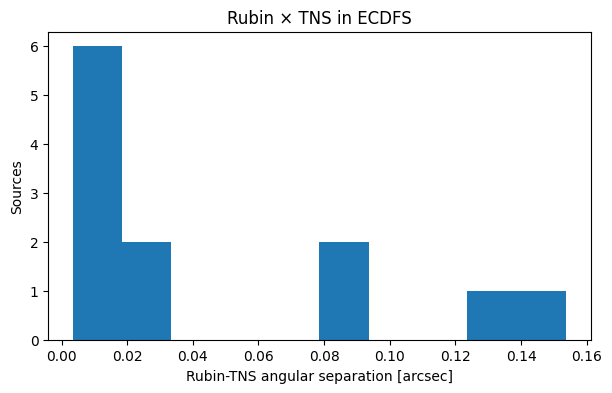

In [ ]:
valid_distance = rubin_tns_best.loc[
    rubin_tns_best["tns_match_ok"],
    "tns_rubin_dist_arcsec"
].dropna()

plt.figure(figsize=(7, 4))
plt.hist(valid_distance, bins=10)

plt.xlabel("Rubin-TNS angular separation [arcsec]")
plt.ylabel("Sources")
plt.title(f"Rubin × TNS in {FIELD}")

plt.show()

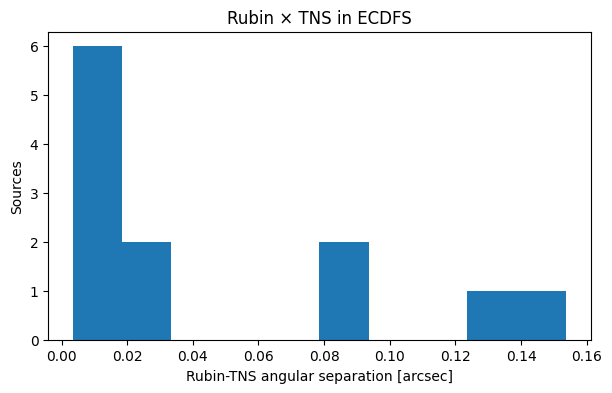

In [ ]:
valid_distance = rubin_tns_best.loc[
    rubin_tns_best["tns_match_ok"],
    "tns_rubin_dist_arcsec"
]

plt.figure(figsize=(7, 4))
plt.hist(valid_distance, bins=10)

plt.xlabel("Rubin-TNS angular separation [arcsec]")
plt.ylabel("Sources")
plt.title(f"Rubin × TNS in {FIELD}")

plt.show()

In [ ]:
try:
    tns_alert_catalog = TNS.crossmatch(
        alerts,
        radius_arcsec=MATCH_RADIUS_ARCSEC,
        n_neighbors=None,
        how="left",
        suffixes=("_tns", "_alert"),
        suffix_method="all_columns",
    )

except (TypeError, ValueError):
    warnings.warn(
        "Using n_neighbors=20 because this LSDB version rejected None."
    )

    tns_alert_catalog = TNS.crossmatch(
        alerts,
        radius_arcsec=MATCH_RADIUS_ARCSEC,
        n_neighbors=20,
        how="left",
        suffixes=("_tns", "_alert"),
        suffix_method="all_columns",
    )

tns_alert_rows = tns_alert_catalog.compute()

print(tns_alert_rows.shape)
print(tns_alert_rows.columns.tolist())
display(tns_alert_rows.head())

In [ ]:
rubin_tns_norm = rubin_tns.rename(
    columns={
        "oid": "rubin_oid",
        "meanra": "rubin_ra",
        "meandec": "rubin_dec",
        "n_det": "rubin_n_det",
        "class_name": "rubin_class",
        "probability": "rubin_probability",
        "classifier_id": "rubin_classifier_id",
    }
)

print("Normalized columns:")
print(rubin_tns_norm.columns.tolist())

display(rubin_tns_norm.head())

Normalized columns:
['rubin_oid', 'tid', 'sid', 'rubin_ra', 'rubin_dec', 'sigmara', 'sigmadec', 'firstmjd', 'lastmjd', 'deltamjd', 'rubin_n_det', 'n_forced', 'n_non_det', 'created_date', 'updated_date', 'rubin_class', 'rubin_probability', 'ranking', 'rubin_classifier_id', 'tns_objid', 'tns_name', 'tns_type', 'tns_redshift', 'tns_ra', 'tns_dec', 'tns_rubin_dist_arcsec', 'tns_match_ok']


,rubin_oid,tid,sid,rubin_ra,rubin_dec,sigmara,sigmadec,firstmjd,lastmjd,deltamjd,rubin_n_det,n_forced,n_non_det,created_date,updated_date,rubin_class,rubin_probability,ranking,rubin_classifier_id,tns_objid,tns_name,tns_type,tns_redshift,tns_ra,tns_dec,tns_rubin_dist_arcsec,tns_match_ok
0,313699514821640259,1,1,51.620550,-28.114119,1.914917e-07,1.884254e-07,60989.260516,61108.032716,118.772200,129,12,0,2026-02-13,2026-03-09,SN,0.965387,1,3,196050,2025aijl,<NA>,NaN,51.620544,-28.114076,0.153674,True
1,313928193878261820,1,1,52.558536,-29.216970,3.142184e-06,3.150095e-06,61041.220126,61060.119674,18.899548,59,0,0,2026-02-13,2026-02-24,SN,0.500874,1,3,174781,2024ahuo,<NA>,NaN,52.716146,-28.990469,954.285790,False
2,313677517043531799,1,1,52.372406,-28.705124,2.131295e-06,2.023052e-06,60984.251250,61088.097015,103.845765,56,1,0,2026-02-13,2026-02-24,SN,0.981978,1,3,143780,2024fw,<NA>,NaN,52.374047,-28.704065,6.432422,False
3,313928193953234970,1,1,54.648409,-27.699329,5.958089e-07,6.076746e-07,61041.220126,61103.036815,61.816689,78,6,0,2026-02-13,2026-03-04,SN,0.685611,1,3,202795,2026fbw,<NA>,NaN,54.648408,-27.699328,0.003441,True
4,313853499427782700,1,1,53.677609,-29.526403,1.229188e-06,1.276612e-06,61024.144244,61069.082988,44.938744,93,0,0,2026-02-13,2026-02-24,SN,0.869342,1,3,203170,2025alvs,<NA>,NaN,53.677617,-29.526406,0.026582,True


In [ ]:
# Quedarnos únicamente con matches válidos
rubin_tns_valid = rubin_tns_best[
    rubin_tns_best["tns_match_ok"]
].copy()

# Resumen por objeto TNS
tns_rubin_summary = (
    rubin_tns_valid.groupby("tns_objid", dropna=False)
    .agg(
        tns_name=("tns_name", "first"),
        tns_type=("tns_type", "first"),
        tns_redshift=("tns_redshift", "first"),

        n_rubin_objects=("rubin_oid", "nunique"),

        rubin_class=("rubin_class", "first"),
        rubin_probability=("rubin_probability", "first"),

        min_sep_arcsec=("tns_rubin_dist_arcsec", "min"),
        median_sep_arcsec=("tns_rubin_dist_arcsec", "median"),
    )
    .reset_index()
)

display(
    tns_rubin_summary
    .sort_values("n_rubin_objects", ascending=False)
    .head(30)
)

,tns_objid,tns_name,tns_type,tns_redshift,n_rubin_objects,rubin_class,rubin_probability,min_sep_arcsec,median_sep_arcsec
0,196050,2025aijl,None,NaN,1,SN,0.965387,0.153674,0.153674
1,200543,2025alrt,None,NaN,1,AGN,0.943000,0.085315,0.085315
2,200546,2025alrv,None,NaN,1,SN,0.865914,0.137300,0.137300
3,200549,2025alry,None,NaN,1,SN,0.984450,0.083974,0.083974
4,202412,2026eqf,SN IIn,0.147,1,SN,0.972766,0.013825,0.013825
5,202644,2026ewn,None,NaN,1,AGN,0.523554,0.011622,0.011622
6,202795,2026fbw,None,NaN,1,SN,0.685611,0.003441,0.003441
7,203170,2025alvs,None,NaN,1,SN,0.869342,0.026582,0.026582
8,204482,2025amka,None,NaN,1,SN,0.806942,0.007878,0.007878
9,207393,2025ammj,None,NaN,1,SN,0.511103,0.009133,0.009133


In [ ]:
safe_to_parquet(
    rubin_tns_valid,
    "rubin_tns_matches.parquet"
)

safe_to_parquet(
    tns_rubin_summary,
    "rubin_tns_summary.parquet"
)

Saved: rubin_tns_matches.parquet
Saved: rubin_tns_summary.parquet
